# Graphlike distance of the circuits as they ship

**Question.** Our full-decoder threshold does not improve the way it should. Are the circuits we
generate structurally different from the ones used in *"Improving the spacetime overhead of dynamic
stabilizer codes by repeating measurements"*
([peter-janderks/floquet_colour_codes_numerics](https://github.com/peter-janderks/floquet_colour_codes_numerics))?

`stim`'s `shortest_graphlike_error()` is the sharpest cheap probe. It succeeds only if some logical
error can be built entirely out of error mechanisms firing at most 2 detectors — exactly the class
MWPM can represent without a lossy decomposition. If it returns nothing, matching is structurally
handicapped on that circuit.

**Every circuit here is used exactly as it comes off disk.** No noise channels are stripped, added,
or reweighted. The DEM is whatever the `.stim` file says it is.

## Families

| family | source | repetition |
|---|---|---|
| `gidney` | `in/circuits/honeycomb_gidney/` (`SDEM3`), d=3,5,7 | none — the un-translated input to our pipeline |
| `ours r=1` | `out/circuits/full_check_pz_rep1/`, d=3,5,7 | none — our Bell translation of the above |
| `ours r=2,3` | `out/circuits/full_check_pz_rep{2,3}/`, d=3,5,7 | our `repeat_measurements()` transform |
| `theirs gf=1` | their `circuits_em3_0.005/`, d=2,4,6,8 | none — gauge factors (1,1,1) |
| `theirs gf=2,3` | their `circuits_em3_0.005/`, d=2,4,6,8 | gauge code, each check measured 2 or 3 times |

We use their **EM3** circuit-level circuits rather than their phenomenological ones, because EM3 is
the same noise family as the `SDEM3` circuits our own pipeline consumes.

In [8]:
import pathlib
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import stim

REPO = pathlib.Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent

GIDNEY = REPO / "in/circuits/honeycomb_gidney"
OURS = REPO / "out/circuits"
THEIRS = REPO / "floquet_colour_codes_numerics/circuit_level_noise_experiments/out/circuits_em3_0.005"

# (rounds, w, h) token -> code distance, from the `expected_distance` field of the Gidney metadata.
OUR_SIZES = {3: "r=10,w=6,h=9", 5: "r=16,w=10,h=15", 7: "r=22,w=14,h=21"}

OUR_R = (1, 2, 3)        # full_check_pz_rep4/5 exist too; add them here if you want them.
THEIR_GF = (1, 2, 3)

# Whether a graphlike logical error *exists* is a property of the DEM's support, not of the
# probabilities, so any pz in the scan gives the same answer. The rep dirs use different pz grids,
# so we just take whichever available value sits closest to this and record it in the table.
PZ_TARGET = 0.01

for p in (GIDNEY, OURS, THEIRS):
    print(f"{'OK ' if p.is_dir() else 'MISSING'} {p.relative_to(REPO)}")

OK  in/circuits/honeycomb_gidney
OK  out/circuits
OK  floquet_colour_codes_numerics/circuit_level_noise_experiments/out/circuits_em3_0.005


## Loaders

Each returns `(circuit, path)` and does nothing to the circuit beyond `stim.Circuit.from_file`.

In [9]:
def gidney_circuit(distance: int):
    path = GIDNEY / f"model=SDEM3,{OUR_SIZES[distance]},p=0.001,obs=H,sheared=False.stim"
    if not path.exists():
        return None, None
    return stim.Circuit.from_file(path), path


def our_circuit(distance: int, r: int):
    """Our biased-Bell translation, r>1 meaning the repeat_measurements() transform was applied."""
    directory = OURS / f"full_check_pz_rep{r}"
    scheme = "biased_bell_v3_equivalent" if r == 1 else f"biased_bell_v3_equivalent_fullrep{r}"
    stem = f"model=SDEM3,{OUR_SIZES[distance]},p=0.001,obs=H,sheared=False__{scheme},pz="
    hits = sorted(directory.glob(f"{stem}*.stim"))
    if not hits:
        return None, None

    # rep1..rep5 each use a different pz grid; pick the value nearest PZ_TARGET.
    def pz_of(path):
        return float(re.search(r"pz=([0-9.e+-]+),p=", path.name).group(1))

    best = min(hits, key=lambda h: abs(pz_of(h) - PZ_TARGET))
    return stim.Circuit.from_file(best), best


def their_circuit(distance: int, gf: int, observable: str):
    """EM3 GaugeHoneycombCode with all three gauge factors equal to `gf` (their X^r Y^r Z^r)."""
    pattern = (f"code_name=GaugeHoneycombCode,per=0.005,noise_model=EM3,distance={distance},"
               f"gf_0={gf},gf_1={gf},gf_2={gf},logical_observable={observable},n_rounds=*.stim")
    hits = sorted(THEIRS.glob(pattern))
    if not hits:
        return None, None
    return stim.Circuit.from_file(hits[0]), hits[0]

## The probe

`approximate_disjoint_errors=True` is required only because their EM3 circuits use
`PAULI_CHANNEL_2`, which stim refuses to expand into a DEM unless asked. It does not alter the
circuits; it is how stim is told to linearise a correlated two-qubit channel. Everything else is
the default DEM.

Alongside the distance we record the DEM's *degree histogram* — how many detectors each error
mechanism fires. Degree ≤ 2 is what MWPM handles natively; degree 3 and 4 must be decomposed.

In [10]:
def to_dem(circuit: stim.Circuit) -> stim.DetectorErrorModel:
    """The circuit's own DEM. `approximate_disjoint_errors` only unlocks PAULI_CHANNEL_2."""
    return circuit.detector_error_model(approximate_disjoint_errors=True)


def graphlike_distance(dem: stim.DetectorErrorModel):
    """Length of the shortest graphlike logical error, or None if there is none."""
    try:
        return len(dem.shortest_graphlike_error(ignore_ungraphlike_errors=True))
    except ValueError:
        return None


def mechanism_degrees(dem: stim.DetectorErrorModel) -> dict[int, int]:
    deg = Counter()
    for inst in dem.flattened():
        if inst.type == "error":
            deg[sum(t.is_relative_detector_id() for t in inst.targets_copy())] += 1
    return dict(sorted(deg.items()))

## The table

One row per circuit file. `gl` is the shortest graphlike error length of the shipped DEM; `NaN`
means `shortest_graphlike_error()` found nothing at all.

In [11]:
rows = []


def record(family, r, distance, observable, circuit, path):
    dem = to_dem(circuit)
    deg = mechanism_degrees(dem)
    n_mech = sum(deg.values())
    n_graphlike = sum(v for k, v in deg.items() if k <= 2)
    gl = graphlike_distance(dem)
    rows.append({
        "family": family,
        "r": r,
        "d": distance,
        "obs": observable,
        "gl": gl,
        "gl/d": (gl / distance) if gl is not None else None,
        "dets": circuit.num_detectors,
        "mechs": n_mech,
        "graphlike_frac": (n_graphlike / n_mech) if n_mech else float("nan"),
        "degrees": deg,
        "file": path.name,
    })
    print(f"{family:<8} r={r} d={distance} {observable:<9} gl={gl}")


for d in (3, 5, 7):
    c, path = gidney_circuit(d)
    if c is not None:
        record("gidney", 1, d, "H", c, path)

for r in OUR_R:
    for d in (3, 5, 7):
        c, path = our_circuit(d, r)
        if c is not None:
            record("ours", r, d, "H", c, path)

for gf in THEIR_GF:
    for d in (2, 4, 6, 8):
        for obs in ("memory_x", "memory_z"):
            c, path = their_circuit(d, gf, obs)
            if c is not None:
                record("theirs", gf, d, obs, c, path)

table = pd.DataFrame(rows)
table

gidney   r=1 d=3 H         gl=3
gidney   r=1 d=5 H         gl=5
gidney   r=1 d=7 H         gl=7
ours     r=1 d=3 H         gl=3
ours     r=1 d=5 H         gl=5
ours     r=1 d=7 H         gl=7
ours     r=2 d=3 H         gl=3
ours     r=2 d=5 H         gl=5
ours     r=2 d=7 H         gl=7
ours     r=3 d=3 H         gl=3
ours     r=3 d=5 H         gl=5
ours     r=3 d=7 H         gl=7
theirs   r=1 d=2 memory_x  gl=2
theirs   r=1 d=2 memory_z  gl=2
theirs   r=1 d=4 memory_x  gl=4
theirs   r=1 d=4 memory_z  gl=4
theirs   r=1 d=6 memory_x  gl=6
theirs   r=1 d=6 memory_z  gl=6
theirs   r=1 d=8 memory_x  gl=8
theirs   r=1 d=8 memory_z  gl=8
theirs   r=2 d=4 memory_x  gl=4
theirs   r=2 d=4 memory_z  gl=4
theirs   r=2 d=6 memory_x  gl=6
theirs   r=2 d=6 memory_z  gl=6
theirs   r=2 d=8 memory_x  gl=8
theirs   r=2 d=8 memory_z  gl=8
theirs   r=3 d=4 memory_x  gl=4
theirs   r=3 d=4 memory_z  gl=4
theirs   r=3 d=6 memory_x  gl=6
theirs   r=3 d=6 memory_z  gl=6
theirs   r=3 d=8 memory_x  gl=8
theirs  

,family,r,d,obs,gl,gl/d,dets,mechs,graphlike_frac,degrees,file
0,gidney,1,3,H,3,1.0,285,2807,0.503741,"{1: 294, 2: 1120, 3: 655, 4: 738}","model=SDEM3,r=10,w=6,h=9,p=0.001,obs=H,sheared..."
1,gidney,1,5,H,5,1.0,1245,15493,0.428452,"{1: 774, 2: 5864, 3: 2679, 4: 6176}","model=SDEM3,r=16,w=10,h=15,p=0.001,obs=H,shear..."
2,gidney,1,7,H,7,1.0,3325,45567,0.404898,"{1: 1478, 2: 16972, 3: 6047, 4: 21070}","model=SDEM3,r=22,w=14,h=21,p=0.001,obs=H,shear..."
3,ours,1,3,H,3,1.0,285,2601,0.548635,"{1: 229, 2: 1198, 3: 521, 4: 653}","model=SDEM3,r=10,w=6,h=9,p=0.001,obs=H,sheared..."
4,ours,1,5,H,5,1.0,1245,14493,0.495619,"{1: 613, 2: 6570, 3: 2069, 4: 5241}","model=SDEM3,r=16,w=10,h=15,p=0.001,obs=H,shear..."
5,ours,1,7,H,7,1.0,3325,42745,0.478629,"{1: 1181, 2: 19278, 3: 4633, 4: 17653}","model=SDEM3,r=22,w=14,h=21,p=0.001,obs=H,shear..."
6,ours,2,3,H,3,1.0,1215,6685,0.579207,"{1: 752, 2: 3120, 3: 1305, 4: 1508}","model=SDEM3,r=10,w=6,h=9,p=0.001,obs=H,sheared..."
7,ours,2,5,H,5,1.0,5165,34177,0.528835,"{1: 2062, 2: 16012, 3: 4827, 4: 11276}","model=SDEM3,r=16,w=10,h=15,p=0.001,obs=H,shear..."
8,ours,2,7,H,7,1.0,13643,97741,0.512661,"{1: 4020, 2: 46088, 3: 10557, 4: 37076}","model=SDEM3,r=22,w=14,h=21,p=0.001,obs=H,shear..."
9,ours,3,3,H,3,1.0,2145,10722,0.578810,"{1: 1172, 2: 5034, 3: 2099, 4: 2417}","model=SDEM3,r=10,w=6,h=9,p=0.001,obs=H,sheared..."


In [12]:
print("shortest graphlike error length, circuits as shipped ('NaN' = none exists)")
view = table.assign(label=lambda t: t.family + " r=" + t.r.astype(str) + " | " + t.obs)
view.pivot_table(index="label", columns="d", values="gl", dropna=False)

shortest graphlike error length, circuits as shipped ('NaN' = none exists)


d,2,3,4,5,6,7,8
label,,,,,,,
gidney r=1 | H,NaN,3.0,NaN,5.0,NaN,7.0,NaN
ours r=1 | H,NaN,3.0,NaN,5.0,NaN,7.0,NaN
ours r=2 | H,NaN,3.0,NaN,5.0,NaN,7.0,NaN
ours r=3 | H,NaN,3.0,NaN,5.0,NaN,7.0,NaN
theirs r=1 | memory_x,2.0,NaN,4.0,NaN,6.0,NaN,8.0
theirs r=1 | memory_z,2.0,NaN,4.0,NaN,6.0,NaN,8.0
theirs r=2 | memory_x,NaN,NaN,4.0,NaN,6.0,NaN,8.0
theirs r=2 | memory_z,NaN,NaN,4.0,NaN,6.0,NaN,8.0
theirs r=3 | memory_x,NaN,NaN,4.0,NaN,6.0,NaN,8.0


In [14]:
# their_circuit(4, 2, "memory_z")[0].diagram("timeline-3d")
# gidney_circuit(3)[0].diagram("matchgraph-3d")
our_circuit(3,1)[0].diagram("matchgraph-3d")

{"accessors":[{"bufferView":0,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":1,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":2,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":3,"byteOffset":0,"componentType":5126,"count":8458,"max":[28.390007019043,36.2057456970215,99.9704055786133],"min":[-7.62870979309082,-12.5346260070801,-6.78702640533447],"name":"buf_scattered_lines","type":"VEC3"},{"bufferView":4,"byteOffset":0,"componentType":5126,"count":816,"max":[16.5,18,90],"min":[-1.5,6,3],"name":"buf_red_scattered_lines","type":"VEC3"}],"asset":{"version":"2.0"},"bufferViews":[{"buffer":0,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":1,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":2,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":3,"byteLength":101496,"byteOffset":0,"name":"buf_scattered_lines","target":34962},{"buffer":4,"byteLength":9792,"byteOffset":0,"name":"buf_red_scattered_lines","target":34962}],"buffers":[{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":101496,"name":"buf_scattered_lines","uri":"data:application/octet-stream;base64,AACQQAAAQEEAAJBBGC88QAAAQEE79QFBAACQQAAAQEEAAEBAAACQQAAAwEAAABBBAACQQAAAQEEAAEBAAACQQAAAwEAAABBBAACQQAAAQEEAAJBBGC88QAAAQEE79QFBAACQQAAAQEEAAJBBGC88QAAAQEE79QFBAACQQAAAQEEAAJBBGC88QAAAQEE79QFBAACQQAAAQEEAAEBAAADwQAAAEEEAAHBBAACQQAAAQEEAAEBAAADwQAAAEEEAAHBBAACQQAAAQEEAAJBBGC88QAAAQEE79QFBAACQQAAAQEEAAEBAAADAPwAAEEEAAHBBAACQQAAAQEEAAEBAAADAPwAAEEEAAHBBAACQQAAAQEEAAJBBGC88QAAAQEE79QFBAADwQAAAQEAAAEBAVjPlQAigeT9SL9nAAADwQAAAQEAAAEBAAACQQAAAwEAAABBBAADwQAAAQEAAAEBAAACQQAAAwEAAABBBAADwQAAAQEAAAJBBufXfQACw9rtbngdBAADwQAAAQEAAAEBAAAAoQQAAwEAAABBBAADwQAAAQEAAAEBAAAAoQQAAwEAAABBBAADwQAAAQEAAAJBBufXfQACw9rtbngdBAADwQAAAQEAAAEBAAADwQAAAEEEAAHBBAADwQAAAQEAAAEBAAADwQAAAEEEAAHBBAADwQAAAQEAAAJBBufXfQACw9rtbngdBAADwQAAAQEAAAEBAAADwQAAAQEAAAJBBAADwQAAAqEEAAEBAVjPlQAAzuEFSL9nAAADwQAAAqEEAAEBAAADwQAAAcEEAABBBAADwQAAAqEEAAEBAAADwQAAAcEEAABBBAADwQAAAqEEAAJBBufXfQGsPwEFbngdBAADwQAAAqEEAAEBAAACQQAAAkEEAAHBBAADwQAAAqEEAAEBAAACQQAAAkEEAAHBBAADwQAAAqEEAAJBBufXfQGsPwEFbngdBAADwQAAAqEEAAEBAAAAoQQAAkEEAAHBBAADwQAAAqEEAAEBAAAAoQQAAkEEAAHBBAADwQAAAqEEAAJBBufXfQGsPwEFbngdBAADwQAAAqEEAAEBAAADwQAAAqEEAAJBBAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAAAoQQAAQEEAAEBAAAAoQQAAwEAAABBBAAAoQQAAQEEAAEBAAAAoQQAAwEAAABBBAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAAAoQQAAQEEAAEBAAADwQAAAEEEAAHBBAAAoQQAAQEEAAEBAAADwQAAAEEEAAHBBAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAAAoQQAAQEEAAEBAAABYQQAAEEEAAHBBAAAoQQAAQEEAAEBAAABYQQAAEEEAAHBBAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAABYQQAAQEAAAEBAPCBoQYD4ez+IxNfAAABYQQAAQEAAAEBAAAAoQQAAwEAAABBBAABYQQAAQEAAAEBAAAAoQQAAwEAAABBBAABYQQAAQEAAAJBBb9JvQYBFtjyZIAlBAABYQQAAQEAAAEBAAACEQQAAwEAAABBBAABYQQAAQEAAAEBAAACEQQAAwEAAABBBAABYQQAAQEAAAJBBb9JvQYBFtjyZIAlBAABYQQAAQEAAAEBAAABYQQAAEEEAAHBBAABYQQAAQEAAAEBAAABYQQAAEEEAAHBBAABYQQ

## Plot: graphlike distance vs code distance

A healthy family sits on a straight line through the origin.

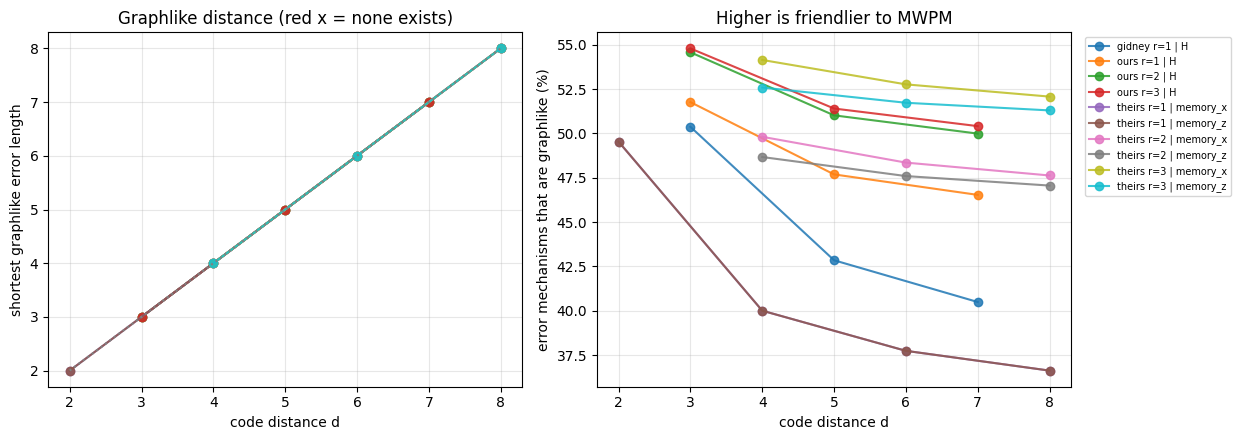

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

for label, grp in view.groupby("label"):
    grp = grp.sort_values("d")
    missing = grp["gl"].isna()
    axes[0].plot(grp["d"], grp["gl"].fillna(0.0), marker="o", label=label, alpha=0.85)
    if missing.any():
        axes[0].scatter(grp["d"][missing], [0] * int(missing.sum()),
                        marker="x", s=120, color="crimson", zorder=5)
    axes[1].plot(grp["d"], 100 * grp["graphlike_frac"], marker="o", label=label, alpha=0.85)

axes[0].plot([2, 8], [2, 8], ls=":", color="grey", label="gl = d")
axes[0].set_ylabel("shortest graphlike error length")
axes[0].set_title("Graphlike distance (red x = none exists)")
axes[1].set_ylabel("error mechanisms that are graphlike (%)")
axes[1].set_title("Higher is friendlier to MWPM")
for ax in axes:
    ax.set_xlabel("code distance d")
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.tight_layout()
plt.show()

## Findings

**Every circuit, ours and theirs, has `gl = d` exactly.** `gl/d = 1.0` in all 32 rows — no `NaN`
anywhere except the (d, family) cells that simply don't exist (our honeycomb is odd-d, their gauge
code is even-d, and their d=2 gf=(2,2,2)/(3,3,3) files were never generated).

| family | d=2 | d=3 | d=4 | d=5 | d=6 | d=7 | d=8 |
|---|---|---|---|---|---|---|---|
| gidney | — | 3 | — | 5 | — | 7 | — |
| ours r=1 | — | 3 | — | 5 | — | 7 | — |
| ours r=2 | — | 3 | — | 5 | — | 7 | — |
| ours r=3 | — | 3 | — | 5 | — | 7 | — |
| theirs gf=1 | 2 | — | 4 | — | 6 | — | 8 |
| theirs gf=2 | — | — | 4 | — | 6 | — | 8 |
| theirs gf=3 | — | — | 4 | — | 6 | — | 8 |

So **the structural hypothesis is dead**. `shortest_graphlike_error()` does not distinguish our
circuits from theirs, and it does not degrade as we repeat measurements. The
`repeat_measurements()` transform preserves the graphlike distance at r=2 and r=3.

The degree histograms say the same thing. Fraction of error mechanisms that MWPM can represent
natively (degree ≤ 2):

| | d=3/4 | d=5/6 | d=7/8 |
|---|---|---|---|
| gidney | 50.4 % | 42.8 % | 40.5 % |
| ours r=1 | 51.8 % | 47.7 % | 46.5 % |
| ours r=2 | 54.6 % | 51.0 % | 50.0 % |
| ours r=3 | 54.8 % | 51.4 % | 50.4 % |
| theirs gf=1 | 40.0 % | 37.7 % | 36.6 % |
| theirs gf=2 | 49.8 % | 48.4 % | 47.6 % |
| theirs gf=3 | 54.1 % | 52.8 % | 52.1 % |

Ours is *friendlier* to matching than theirs at every r, and repetition improves the fraction on
both sides by about the same amount (+3 pts per extra repetition, saturating by r=3). Our r=2
already sits where their gf=2 sits.

### What this rules out, and what it doesn't

Ruled out: the claim in `docs/repeated_measurements_summary.md` that *"pure-p_z logical errors in
these circuits are non-graphlike — `shortest_graphlike_error()` finds nothing at any r"*. That was
measured on a circuit with the measurement noise artificially isolated, and it was an artifact of
`p_m = 0.0` making the boundary measurements exactly noiseless. On the circuits as they are actually
decoded — `pz ≈ 0.01` with `p_res = 1e-6` — the graphlike sector is intact and full-distance.

Not ruled out: this probe counts *mechanisms*, not weight. `gl = d` says a degree-≤2 logical error
exists; it says nothing about whether the minimum-*weight* graphlike error is built from `pz` edges
or from the 1e-6 residual edges, nor about how much likelihood MWPM throws away when it decomposes
the 46–63 % of mechanisms that are degree 3 or 4. That is the next thing to measure.

In [24]:
our_circuit_0pres = stim.Circuit.from_file(OURS / "full_check_pz_rep1_0pres/model=SDEM3,r=10,w=6,h=9,p=0.001,obs=H,sheared=False__biased_bell_v3_equivalent,pz=0.2,p=0.stim")
our_circuit_0pres_2rep = stim.Circuit.from_file(OURS / "full_check_pz_rep2_0pres/model=SDEM3,r=10,w=6,h=9,p=0.001,obs=H,sheared=False__biased_bell_v3_equivalent_fullrep2,pz=0.1,p=0.stim")
print(graphlike_distance(to_dem(our_circuit_0pres_2rep)))

None


In [20]:
our_circuit_0pres.diagram("matchgraph-3d")

{"accessors":[{"bufferView":0,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":1,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":2,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":3,"byteOffset":0,"componentType":5126,"count":256,"max":[16.5,27,99.7208251953125],"min":[-0.164817929267883,-0.846405506134033,-6.65594387054443],"name":"buf_scattered_lines","type":"VEC3"},{"bufferView":4,"byteOffset":0,"componentType":5126,"count":4,"max":[10.5,18,90],"min":[4.5,15,87],"name":"buf_red_scattered_lines","type":"VEC3"},{"bufferView":5,"byteOffset":0,"componentType":5126,"count":1986,"max":[19.5,27,90],"min":[-1.5,0,3],"name":"buf_blue_scattered_lines","type":"VEC3"},{"bufferView":6,"byteOffset":0,"componentType":5126,"count":348,"max":[13.5,18,90],"min":[1.5,9,3],"name":"buf_purple_scattered_lines","type":"VEC3"}],"asset":{"version":"2.0"},"bufferViews":[{"buffer":0,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":1,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":2,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":3,"byteLength":3072,"byteOffset":0,"name":"buf_scattered_lines","target":34962},{"buffer":4,"byteLength":48,"byteOffset":0,"name":"buf_red_scattered_lines","target":34962},{"buffer":5,"byteLength":23832,"byteOffset":0,"name":"buf_blue_scattered_lines","target":34962},{"buffer":6,"byteLength":4176,"byteOffset":0,"name":"buf_purple_scattered_lines","target":34962}],"buffers":[{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":3072,"name":"buf_scattered_lines","uri":"data:application/octet-stream;base64,AADwQAAAQEAAAEBAAADwQAAAQEAAAJBBAADwQAAAqEEAAEBAAADwQAAAqEEAAJBBAABYQQAAQEAAAEBAAABYQQAAQEAAAJBBAABYQQAAqEEAAEBAAABYQQAAqEEAAJBBAADAPwAAQEAAAEBACMYovrNIgD9+/dTAAACEQQAAQEEAAEBAAABYQQAAEEEAAHBBAADAPwAAqEEAAEBAAACQQAAAkEEAAHBBAADAPwAAcEEAABBBAADAPwAAcEEAANhBAACQQAAAwEAAABBBAACQQAAAwEAAAEBBAACQQAAAwEAAABBBAACQQAAAwEAAANhBAADwQAAAcEEAABBBAADwQAAAcEEAANhBAAAoQQAAwEAAABBBAAAoQQAAwEAAAEBBAAAoQQAAwEAAABBBAAAoQQAAwEAAANhBAABYQQAAcEEAABBBAABYQQAAcEEAANhBAACEQQAAwEAAABBBAACEQQAAwEAAAEBBAACEQQAAwEAAABBBAACEQQAAwEAAANhBAACEQQAAwEAAAEBBAACEQQAAwEAAANhBAAAoQQAAwEEAAEBBAAAoQQAAkEEAAHBBAACEQQAAwEEAAEBBAACEQQAAkEEAAHBBAACQQAAAwEEAAEBBAACQQAAAkEEAAHBBAACQQAAAQEEAAJBBGC88QAAAQEE79QFBAACQQAAAQEEAAJBBAACQQAAAQEEAABBCAADwQAAAQEAAAJBBufXfQACw9rtbngdBAADwQAAAQEAAAJBBAADwQAAAQEAAABBCAADwQAAAqEEAAJBBufXfQGsPwEFbngdBAADwQAAAqEEAAJBBAADwQAAAqEEAABBCAAAoQQAAQEEAAJBBz2gwQQAAQEGdOABBAAAoQQAAQEEAAJBBAAAoQQAAQEEAABBCAABYQQAAQEAAAJBBb9JvQYBFtjyZIAlBAABYQQAAQEAAAJBBAABYQQAAQEAAAKhBAABYQQAAQEAAAJBBAABYQQAAQEAAABBCAABYQQAAqEEAAJBBb9JvQW/Sv0GZIAlBAABYQQAAqEEAAJBBAABYQQAAqEEAABBCAABYQQAAQEAAAKhBAABYQQAAQEAAABBCAADAPwAAQEAAAKhBAACQQAAAAAAAAMBBAADAPwAAcEEAANhBAADAPwAAcEEAADRCAACQQAAAwEAAANhBAACQQAAAwEAAADRCAADwQAAAcEEAANhBAADwQAAAcEEAADRCAAAoQQAAwEAAANhBAAAoQQAAwEAAADRCAABYQQAAcEEAANhBAABYQQAAcEEAADRCAACEQQAAwEAAANhBAACEQQAA

In [25]:
our_circuit_0pres_2rep.diagram("matchgraph-3d")

{"accessors":[{"bufferView":0,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":1,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":2,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":3,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":4,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":5,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":6,"byteOffset":0,"componentType":5126,"count":1758,"max":[129.311569213867,132.475616455078,90],"min":[-7.92844343185425,-8.00793266296387,-10.9932146072388],"name":"buf_scattered_lines","type":"VEC3"},{"bufferView":7,"byteOffset":0,"componentType":5126,"count":100,"max":[108,105,87],"min":[0,-7.64872026443481,-9.61630725860596],"name":"buf_red_scattered_lines","type":"VEC3"},{"bufferView":8,"byteOffset":0,"componentType":5126,"count":2576,"max":[114,120,90],"min":[-1.5,0,-1],"name":"buf_blue_scattered_lines","type":"VEC3"}],"asset":{"version":"2.0"},"bufferViews":[{"buffer":0,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":1,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":2,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":3,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":4,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":5,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":6,"byteLength":21096,"byteOffset":0,"name":"buf_scattered_lines","target":34962},{"buffer":7,"byteLength":1200,"byteOffset":0,"name":"buf_red_scattered_lines","target":34962},{"buffer":8,"byteLength":30912,"byteOffset":0,"name":"buf_blue_scattered_lines","target":34962}],"buffers":[{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":21096,"name":"buf_scattered_lines","uri":"data:application/octet-stream;bas